# 🔁 Lesson 11 · Recurrent Networks: RNN, LSTM & GRU

*“Memory is what turns a snapshot into a story.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~130 min | 🟠 Intermediate → Advanced | Day 9–10 | Lessons 04–06 (backprop!), shapes |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Explain why **order matters** for sequence data and what a **hidden state** is
- Implement a **vanilla RNN** forward pass from scratch and count its parameters
- Explain **vanishing and exploding gradients through time**: and how clipping and gating address them
- Describe the **LSTM** (forget / input / output gates, cell state) and **GRU** (update / reset gates); implement an LSTM cell and **verify it against PyTorch**
- Use `nn.RNN / nn.LSTM / nn.GRU` correctly: shapes, `batch_first`, `h_n`, `c_n`
- Show experimentally that gated networks remember **long-range** information vanilla RNNs forget
- Turn a time series into supervised-learning **windows** (the key step for Project 4)

## 🗺 Roadmap
1. Why sequences need memory
2. The vanilla RNN
3. Gradients through time
4. The LSTM
5. The GRU
6. Parameter counts
7. The PyTorch API & shapes
8. Experiment: who remembers longest?
9. Practical tips
10. Windowing time series
11. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
cpu = torch.device('cpu')
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 🧠 1. Why sequences need memory

Some data only makes sense **in order**:

* 📈 *Prices:* this week's price depends on the last several weeks.
* 🌦 *Weather / sensor streams:* soil moisture now depends on rain over the past days.
* 📝 *Text:* "the farmer sold **her** maize": what does *her* refer to?
* 🎤 *Audio, DNA, music…*

A fully-connected or conv network sees a fixed-size input with no sense of time. A **recurrent neural network (RNN)** processes a sequence **one step at a time**, carrying a **hidden state** $h_t$ (a running summary of everything seen so far) from step to step.

> 🌽 **Analogy.** A market trader reading a daily price list. After each day she updates her *mental summary* ("prices trending up, lean season approaching"). Tomorrow's reading is interpreted **through that summary**. The summary is $h_t$; the update rule is the RNN's weights; the *same* rule is used every day (**parameter sharing across time**).

**Data shape for sequences:** `(batch, time_steps, features)`: e.g. 32 farms × 52 weeks × 3 variables (price, rainfall, fuel).

---
## 🔄 2. The vanilla RNN

At every time step $t$, with input $x_t$ and previous state $h_{t-1}$:

$$h_t=\tanh\!\big(x_tW_{xh}+h_{t-1}W_{hh}+b\big)$$

* $W_{xh}$ (`input × hidden`): how the new input affects the state,
* $W_{hh}$ (`hidden × hidden`): how the old state carries forward,
* the **same** $W_{xh},W_{hh},b$ are reused at every step. Parameters: $n_{in}\!\cdot\! n_h+n_h^2+n_h$: **independent of sequence length**.

```
   x₁        x₂        x₃              each box is the SAME cell
    ↓         ↓         ↓
h₀ →[ RNN ]→ h₁ →[ RNN ]→ h₂ →[ RNN ]→ h₃ → (prediction)
```

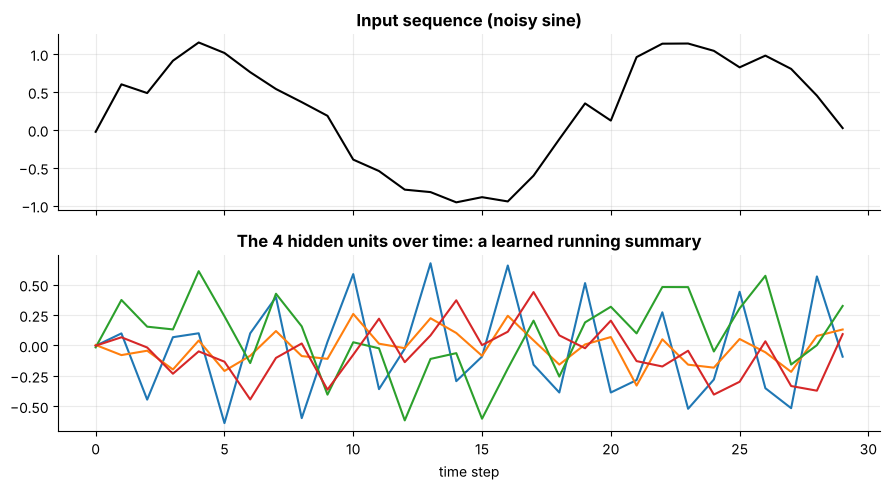

hidden-state matrix shape (T, hidden): (30, 4) | parameters: 24


In [2]:
def rnn_forward(x_seq, Wxh, Whh, b, h0=None):
    """x_seq: (T, n_in). Returns all hidden states (T, n_hidden)."""
    h = np.zeros(Whh.shape[0]) if h0 is None else h0
    states = []
    for x_t in x_seq:                                  # one step at a time: this loop IS the recurrence
        h = np.tanh(x_t @ Wxh + h @ Whh + b)
        states.append(h)
    return np.array(states)

rng = np.random.default_rng(0)
n_in, n_h, T = 1, 4, 30
Wxh, Whh, b = rng.normal(0, 1.0, (n_in, n_h)), rng.normal(0, 0.6, (n_h, n_h)), np.zeros(n_h)
t = np.arange(T); x_seq = (np.sin(t / 3) + 0.2 * rng.normal(size=T))[:, None]
H = rnn_forward(x_seq, Wxh, Whh, b)
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax[0].plot(x_seq, "k"); ax[0].set_title("Input sequence (noisy sine)")
ax[1].plot(H); ax[1].set_title("The 4 hidden units over time: a learned running summary"); ax[1].set_xlabel("time step")
plt.tight_layout(); plt.show()
print("hidden-state matrix shape (T, hidden):", H.shape, "| parameters:", Wxh.size + Whh.size + b.size)

---
## ⏪ 3. Gradients through time: the long-memory problem

Training uses **backpropagation through time (BPTT)**: unroll the loop into a deep network (one layer per time step, all sharing weights) and backprop as in Lesson 04. To let a loss at step $T$ teach the network about an input at step $1$, the gradient must travel back $T-1$ steps:

$$\frac{\partial h_T}{\partial h_1}=\prod_{t=2}^{T}\operatorname{diag}\big(1-h_t^2\big)\,W_{hh}^{\top}$$

A product of $T$ matrices **shrinks exponentially** if their typical size is < 1 (*vanishing* (the network can't learn long-range dependencies) or **explodes** if > 1 (*exploding*) unstable training, `nan`). Let's measure it:

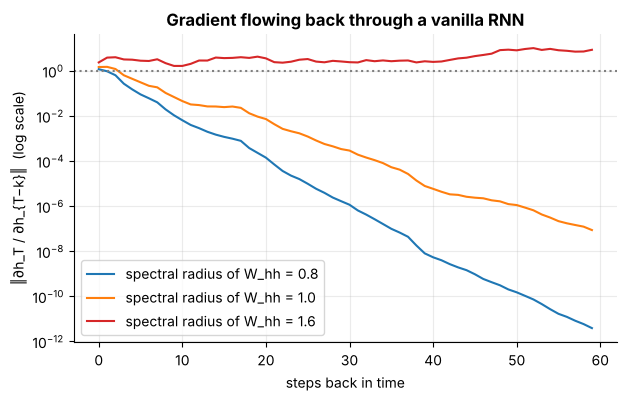

In [3]:
def grad_norm_through_time(scale, T=60, n_h=32, seed=0):
    rng = np.random.default_rng(seed)
    W = rng.normal(0, 1, (n_h, n_h)); W *= scale / np.max(np.abs(np.linalg.eigvals(W)))     # set the spectral radius to `scale`
    Wxh = rng.normal(0, 0.5, (1, n_h)); h = np.zeros(n_h)
    J, norms = np.eye(n_h), []
    for t in range(T):
        h = np.tanh(rng.normal(size=1) @ Wxh + h @ W)
        J = J @ (np.diag(1 - h ** 2) @ W.T)                   # chain rule: multiply in one more Jacobian
        norms.append(np.linalg.norm(J, 2))
    return norms

for scale, c in [(0.8, "C0"), (1.0, "C1"), (1.6, "C3")]:
    plt.semilogy(grad_norm_through_time(scale), c, label=f"spectral radius of W_hh = {scale}")
plt.xlabel("steps back in time"); plt.ylabel("‖∂h_T / ∂h_{T−k}‖  (log scale)"); plt.legend(); plt.title("Gradient flowing back through a vanilla RNN")
plt.axhline(1, c="gray", ls=":"); plt.show()

With the tanh slopes (always ≤ 1) included, even a radius of 1.0 decays; larger radii blow up (and tanh's saturation keeps hidden states bounded while gradients explode). **Remedies**

| Problem | Remedy |
|:--|:--|
| **Exploding** gradients | **Gradient clipping**: rescale gradients if their norm exceeds a threshold (`torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)`) |
| **Vanishing** gradients | **Gated architectures**: LSTM and GRU: give the gradient a more direct path through time |

---
## 🚪 4. The LSTM: memory with gates

The **Long Short-Term Memory** cell (Hochreiter & Schmidhuber, 1997) separates *what it remembers* (a **cell state** $c_t$) from *what it shows the world*: the hidden state $h_t$. Three **gates** (sigmoids, outputs in (0,1) = "how much") control the flow:

$$\begin{aligned}
f_t&=\sigma(x_tW_f+h_{t-1}U_f+b_f)&&\text{forget gate: how much old memory to keep}\\
i_t&=\sigma(x_tW_i+h_{t-1}U_i+b_i)&&\text{input gate: how much new info to write}\\
g_t&=\tanh(x_tW_g+h_{t-1}U_g+b_g)&&\text{candidate: the new info itself}\\
o_t&=\sigma(x_tW_o+h_{t-1}U_o+b_o)&&\text{output gate: how much memory to reveal}\\
c_t&=f_t\odot c_{t-1}+i_t\odot g_t&&\text{update the cell state}\\
h_t&=o_t\odot\tanh(c_t)&&\text{new hidden state}
\end{aligned}$$

> 🌽 **Analogy: the farmer's ledger.** $c_t$ is a notebook. Each day: the **forget gate** crosses out outdated entries ("last season's rainfall: no longer relevant"); the **input gate** decides which of today's observations to write down; the **output gate** decides what to *say aloud* today based on the notebook. Because $c_t$ is updated by *adding* (not repeatedly squashing through tanh), information, and gradients, can flow across many steps when the forget gate stays near 1. **That additive highway is the whole trick.**

Let's implement one LSTM step and **verify it against PyTorch's `nn.LSTMCell`** by copying its weights. (PyTorch stacks the four gates' weights in the order **i, f, g, o**.)

In [4]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))

def lstm_cell(x, h, c, W_ih, W_hh, b_ih, b_hh):
    """One LSTM step. Shapes follow PyTorch: W_ih (4H, n_in), W_hh (4H, H), biases (4H,)."""
    gates = x @ W_ih.T + b_ih + h @ W_hh.T + b_hh
    i, f, g, o = np.split(gates, 4, axis=-1)
    i, f, o, g = sigmoid(i), sigmoid(f), sigmoid(o), np.tanh(g)
    c_new = f * c + i * g                  # forget some old memory, write some new
    h_new = o * np.tanh(c_new)             # reveal part of the memory
    return h_new, c_new

torch.manual_seed(0)
cell = nn.LSTMCell(3, 5)
x = torch.randn(2, 3); h0 = torch.randn(2, 5); c0 = torch.randn(2, 5)
h_t, c_t = cell(x, (h0, c0))
p = {k: v.detach().numpy() for k, v in cell.named_parameters()}
h_np, c_np = lstm_cell(x.numpy(), h0.numpy(), c0.numpy(), p["weight_ih"], p["weight_hh"], p["bias_ih"], p["bias_hh"])
print("our LSTM matches PyTorch: hidden:", np.allclose(h_np, h_t.detach().numpy(), atol=1e-6), "| cell:", np.allclose(c_np, c_t.detach().numpy(), atol=1e-6))

our LSTM matches PyTorch: hidden: True | cell: True


---
## ⚙️ 5. The GRU: a leaner gated cell

The **Gated Recurrent Unit** (Cho et al., 2014) merges the cell and hidden state and uses **two gates**:

$$\begin{aligned}
r_t&=\sigma(x_tW_r+h_{t-1}U_r+b_r)&&\text{reset gate: how much past to use when proposing new content}\\
z_t&=\sigma(x_tW_z+h_{t-1}U_z+b_z)&&\text{update gate: how much to keep old state vs. replace it}\\
n_t&=\tanh\big(x_tW_n+b_{in}+r_t\odot(h_{t-1}U_n+b_{hn})\big)&&\text{candidate state}\\
h_t&=(1-z_t)\odot n_t+z_t\odot h_{t-1}&&\text{blend}
\end{aligned}$$

**LSTM vs GRU:** GRU has ~25 % fewer parameters and trains a bit faster; LSTM has a separate memory and can be slightly stronger on very long dependencies. In practice **try both**: differences are often small. (You'll implement the GRU cell as a problem.)

### Parameter counts (PyTorch convention: two bias vectors per gate-block)
| Cell | Gate blocks | Parameters ($n_{in}=i$, hidden $=h$) |
|:--|:-:|:--|
| RNN | 1 | $h\,i+h^2+2h$ |
| GRU | 3 | $3\,(h\,i+h^2+2h)$ |
| LSTM | 4 | $4\,(h\,i+h^2+2h)$ |

In [5]:
i, h = 10, 32
for name, mod, blocks in [("RNN", nn.RNN(i, h), 1), ("GRU", nn.GRU(i, h), 3), ("LSTM", nn.LSTM(i, h), 4)]:
    print(f"{name:5s} formula {blocks * (h * i + h * h + 2 * h):6d} | PyTorch {dl.count_params(mod):6d}")

RNN   formula   1408 | PyTorch   1408
GRU   formula   4224 | PyTorch   4224
LSTM  formula   5632 | PyTorch   5632


---
## 🧰 6. The PyTorch API: and its shapes

In [6]:
lstm = nn.LSTM(input_size=3, hidden_size=16, num_layers=2, batch_first=True)      # batch_first → (batch, time, features)
x = torch.randn(8, 20, 3)                                                           # 8 sequences, 20 steps, 3 features
out, (h_n, c_n) = lstm(x)
print("input   :", tuple(x.shape),   " (batch, time, features)")
print("out     :", tuple(out.shape),  " hidden state at EVERY time step of the LAST layer: (batch, time, hidden)")
print("h_n     :", tuple(h_n.shape),  " final hidden state of EACH layer: (num_layers, batch, hidden)")
print("c_n     :", tuple(c_n.shape),  " final cell state of each layer")
print("out[:, -1] equals h_n[-1]:", torch.allclose(out[:, -1], h_n[-1]))

input   : (8, 20, 3)  (batch, time, features)
out     : (8, 20, 16)  hidden state at EVERY time step of the LAST layer: (batch, time, hidden)
h_n     : (2, 8, 16)  final hidden state of EACH layer: (num_layers, batch, hidden)
c_n     : (2, 8, 16)  final cell state of each layer
out[:, -1] equals h_n[-1]: True


**Typical wiring**: a *many-to-one* model for classification or forecasting:

```python
class SeqModel(nn.Module):
    def __init__(self, n_in, hidden, n_out):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, batch_first=True)
        self.head = nn.Linear(hidden, n_out)
    def forward(self, x):                  # x: (B, T, n_in)
        out, _ = self.rnn(x)
        return self.head(out[:, -1])       # use the LAST time step's hidden state
```

* `batch_first=True`: **always set it**; the default `(time, batch, features)` is a notorious source of silent bugs.
* `bidirectional=True` reads the sequence both ways (output size doubles). Great for text *understanding*, **wrong for forecasting** (it would peek at the future!).
* `num_layers>1` stacks RNNs; `dropout=` between layers regularises.

---
## 🧪 7. Experiment: who remembers longest?

A classic memory test is the **adding problem** (Hochreiter & Schmidhuber, 1997). Each input step has **two numbers**: a random value in [0, 1] and a **marker** (0 or 1). Exactly two steps are marked: one in the first half of the sequence, one in the second half. The target is the **sum of the two marked values**.

To succeed the network must *notice* a marker, *store* its value, ignore the hundreds of unmarked steps, then *add* it to the second marked value. Predicting the average (always answering 1.0) gives an MSE of about **0.167**: that is the "learned nothing" level. We train a vanilla RNN, a GRU and an LSTM of the same hidden size on sequences of increasing length $T$.

RNN   T=10: MSE 0.0061   T=50: MSE 0.1777   T=100: MSE 0.1687
GRU   T=10: MSE 0.0001   T=50: MSE 0.0003   T=100: MSE 0.0006
LSTM  T=10: MSE 0.0002   T=50: MSE 0.0013   T=100: MSE 0.0020


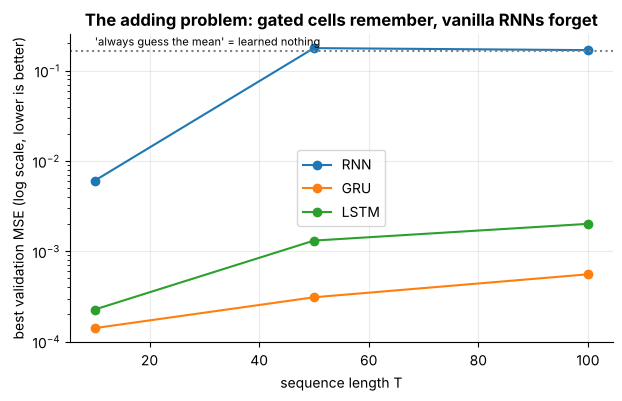

In [7]:
def make_adding_data(n, T, seed):
    rng = np.random.default_rng(seed)
    vals = rng.uniform(0, 1, (n, T)).astype("float32"); mask = np.zeros((n, T), "float32")
    r = np.arange(n)
    mask[r, rng.integers(0, T // 2, n)] = 1; mask[r, rng.integers(T // 2, T, n)] = 1      # one marker in each half
    y = (vals * mask).sum(1, keepdims=True).astype("float32")
    return torch.tensor(np.stack([vals, mask], -1)), torch.tensor(y)               # x: (n, T, 2), y: (n, 1)

class SeqRegressor(nn.Module):
    def __init__(self, kind, hidden=32):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[kind](2, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])                    # many-to-one: read the last step

def run(kind, T, epochs=25):
    dl.set_seed(0)
    Xa, Ya = make_adding_data(3000, T, 0); Xb, Yb = make_adding_data(600, T, 1)
    tr = DataLoader(TensorDataset(Xa, Ya), batch_size=64, shuffle=True); va = DataLoader(TensorDataset(Xb, Yb), batch_size=600)
    m = SeqRegressor(kind)
    h = dl.fit(m, tr, va, nn.MSELoss(), torch.optim.Adam(m.parameters(), lr=5e-3), epochs=epochs, device=cpu,
               grad_clip=1.0, task="regression", verbose=False)
    return min(h["val_loss"])

lengths = [10, 50, 100]
table = {kind: [run(kind, T) for T in lengths] for kind in ["RNN", "GRU", "LSTM"]}
for kind, mses in table.items(): print(f"{kind:5s}", "   ".join(f"T={T}: MSE {m:.4f}" for T, m in zip(lengths, mses)))
for kind, mses in table.items(): plt.semilogy(lengths, mses, "o-", label=kind)
plt.axhline(0.167, c="gray", ls=":"); plt.annotate("'always guess the mean' = learned nothing", (lengths[0], 0.19), fontsize=8)
plt.xlabel("sequence length T"); plt.ylabel("best validation MSE (log scale, lower is better)"); plt.legend(); plt.title("The adding problem: gated cells remember, vanilla RNNs forget"); plt.show()

**How to read it.** At $T=10$ every model copes. By $T=50$ the vanilla RNN's error sits at the *predict-the-mean* level: the gradient from the loss can no longer reach the first marker, so it never learns to store it. The GRU and LSTM keep the error orders of magnitude lower, even at $T=100$. *Exact digits vary with seed and training budget: the gap is the lesson.*

> 🔎 **Honest note.** Simpler memory tasks (e.g. "remember a single bit") can be solved by a vanilla RNN even at long lengths, because a saturated tanh unit can hold one bit stubbornly. The adding problem is harder because the network must *accumulate* and *combine* values, which is much closer to what forecasting asks of a model.

---
## 🛠 8. Practical tips

| Tip | Why |
|:--|:--|
| **Clip gradients** (`grad_clip=1.0` in `dl.fit`) | RNN losses are spiky; clipping prevents explosions |
| **Scale inputs** (standardise features) | Saturated tanh/sigmoid kill learning |
| **Start with GRU or LSTM**, not vanilla RNN | Better long-range memory, same API |
| **Keep sequences as short as the task allows** | Cost grows with length; BPTT is sequential (hard to parallelise) → motivates Transformers (Lesson 13) |
| **Don't use `bidirectional` for forecasting** | It would see the future |
| Padding variable-length sequences | Use `pad_sequence` + `pack_padded_sequence` so padding doesn't pollute the state |
| **Split time series chronologically** | Random splits leak the future into training (Project 4) |

---
## 🪟 9. From a time series to supervised learning: windows

A forecaster needs `(inputs, target)` pairs. We slide a **window** along the series: the last `window` observations are the input; the value `horizon` steps after the window is the target. Example for window = 3, horizon = 1 on `[10, 20, 30, 40, 50, 60]`:

| Input window | Target |
|:--|:--|
| `[10, 20, 30]` | `40` |
| `[20, 30, 40]` | `50` |
| `[30, 40, 50]` | `60` |

You'll implement this in Problem 4, and use it all through Project 4.

In [8]:
series = np.arange(10, 70, 10)
window, horizon = 3, 1
X = np.stack([series[i:i + window] for i in range(len(series) - window - horizon + 1)])
y = np.array([series[i + window + horizon - 1] for i in range(len(series) - window - horizon + 1)])
print(X, "→", y)

[[10 20 30]
 [20 30 40]
 [30 40 50]] → [40 50 60]


---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 11.1: Vanilla RNN, forward pass  &nbsp; `⭐⭐`

Implement `rnn_forward(x_seq, Wxh, Whh, b)` returning all hidden states `(T, n_hidden)` with $h_0=0$ and $h_t=\tanh(x_tW_{xh}+h_{t-1}W_{hh}+b)$. The check compares with PyTorch's `nn.RNN`.

<details><summary>💡 Hint 1</summary>

Start with `h = np.zeros(Whh.shape[0])` and an empty list.

</details>

<details><summary>💡 Hint 2</summary>

Loop over rows of `x_seq`: `h = np.tanh(x_t @ Wxh + h @ Whh + b)`; append.

</details>

<details><summary>💡 Hint 3</summary>

Return `np.array(states)`.

</details>


In [ ]:
def rnn_forward(x_seq, Wxh, Whh, b):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
torch.manual_seed(1)
rnn = nn.RNN(3, 4, batch_first=True)
x = torch.randn(1, 6, 3)
ref, _ = rnn(x)
p = {k: v.detach().numpy() for k, v in rnn.named_parameters()}
mine = rnn_forward(x[0].numpy(), p["weight_ih_l0"].T, p["weight_hh_l0"].T, p["bias_ih_l0"] + p["bias_hh_l0"])
dl.check("hidden states match nn.RNN", mine is not None and mine.shape == (6, 4) and np.allclose(mine, ref[0].detach().numpy(), atol=1e-6))

---
### 🧩 Problem 11.2: Count recurrent parameters  &nbsp; `⭐`

Write `rnn_params(i, h)`, `gru_params(i, h)` and `lstm_params(i, h)` using the PyTorch convention (two bias vectors).

<details><summary>💡 Hint 1</summary>

One 'gate block' has `h*i + h*h + 2*h` parameters.

</details>

<details><summary>💡 Hint 2</summary>

RNN has 1 block, GRU 3, LSTM 4.

</details>


In [ ]:
def rnn_params(i, h):
    pass
def gru_params(i, h):
    pass
def lstm_params(i, h):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
for name, f, mod in [("RNN", rnn_params, nn.RNN), ("GRU", gru_params, nn.GRU), ("LSTM", lstm_params, nn.LSTM)]:
    v = f(7, 16)
    dl.check(f"{name} formula equals PyTorch", v is not None and v == dl.count_params(mod(7, 16)))

---
### 🧩 Problem 11.3: A GRU cell from scratch  &nbsp; `⭐⭐⭐`

Implement `gru_cell(x, h, W_ih, W_hh, b_ih, b_hh)` (NumPy, shapes as in PyTorch: `W_ih (3H, n_in)`, `W_hh (3H, H)`, biases `(3H,)`; gate order **r, z, n**).
Use $r=\sigma(\dots),\ z=\sigma(\dots),\ n=\tanh(W_{in}x+b_{in}+r\odot(W_{hn}h+b_{hn})),\ h'=(1-z)\odot n+z\odot h$. It must match `nn.GRUCell`.

<details><summary>💡 Hint 1</summary>

`gi = x @ W_ih.T + b_ih`; `gh = h @ W_hh.T + b_hh`; then `np.split(..., 3, axis=-1)` each into (r, z, n) parts.

</details>

<details><summary>💡 Hint 2</summary>

`r = sigmoid(gi_r + gh_r)`, `z = sigmoid(gi_z + gh_z)`.

</details>

<details><summary>💡 Hint 3</summary>

`n = tanh(gi_n + r * gh_n)`: note the reset gate multiplies only the *hidden* part, **including its bias**.

</details>

<details><summary>💡 Hint 4</summary>

`h_new = (1 - z) * n + z * h`.

</details>


In [ ]:
def gru_cell(x, h, W_ih, W_hh, b_ih, b_hh):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
torch.manual_seed(2)
cell = nn.GRUCell(3, 5); x = torch.randn(4, 3); h = torch.randn(4, 5)
ref = cell(x, h).detach().numpy()
p = {k: v.detach().numpy() for k, v in cell.named_parameters()}
mine = gru_cell(x.numpy(), h.numpy(), p["weight_ih"], p["weight_hh"], p["bias_ih"], p["bias_hh"])
dl.check("matches nn.GRUCell", mine is not None and np.allclose(mine, ref, atol=1e-6))

---
### 🧩 Problem 11.4: Sliding windows  &nbsp; `⭐⭐`

Write `make_windows(series, window, horizon=1)` for a 1-D NumPy array. Return `(X, y)`: `X` has shape `(N, window)`, `y` has shape `(N,)`, where
`X[k] = series[k : k+window]` and `y[k] = series[k + window + horizon − 1]`, and `N = len(series) − window − horizon + 1`.

<details><summary>💡 Hint 1</summary>

Compute `N` first.

</details>

<details><summary>💡 Hint 2</summary>

A list comprehension over `range(N)` works; for speed use `np.lib.stride_tricks.sliding_window_view`.

</details>

<details><summary>💡 Hint 3</summary>

Check the last window ends **before** the last target.

</details>


In [ ]:
def make_windows(series, window, horizon=1):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
s = np.arange(10, 70, 10)
r = make_windows(s, 3, 1)
dl.check("3 windows of width 3", r is not None and r[0].shape == (3, 3))
dl.check("first window and target: [10,20,30] → 40", r is not None and list(r[0][0]) == [10, 20, 30] and r[1][0] == 40)
dl.check("last target is 60", r is not None and r[1][-1] == 60)
r2 = make_windows(s, 2, 3)
dl.check("horizon=3: [10,20] → 50 and count = 6−2−3+1 = 2", r2 is not None and len(r2[1]) == 2 and list(r2[0][0]) == [10, 20] and r2[1][0] == 50)

---
### 🧩 Problem 11.5: Predict the shapes  &nbsp; `⭐`

Consider `lstm = nn.LSTM(10, 20, num_layers=2, batch_first=True, bidirectional=True)` and an input of shape `(8, 15, 10)`.
Without running it, fill the dictionary `shapes` with the shapes (tuples) of `out`, `h_n` and `c_n`. Then run it to verify.

<details><summary>💡 Hint 1</summary>

Bidirectional doubles the feature size of `out`: `2 × hidden`.

</details>

<details><summary>💡 Hint 2</summary>

`h_n` and `c_n` have shape `(num_layers × num_directions, batch, hidden)`.

</details>


In [ ]:
shapes = {"out": None, "h_n": None, "c_n": None}

In [ ]:
# ▶ self-check (run after you've written your answer)
lstm = nn.LSTM(10, 20, num_layers=2, batch_first=True, bidirectional=True)
o, (h, c) = lstm(torch.randn(8, 15, 10))
dl.check("out shape", shapes["out"] == tuple(o.shape))
dl.check("h_n shape", shapes["h_n"] == tuple(h.shape))
dl.check("c_n shape", shapes["c_n"] == tuple(c.shape))

---
## 🏁 Key takeaways
- ✅ An **RNN** processes a sequence step by step, carrying a **hidden state**; weights are **shared across time**.
- ✅ Training uses **BPTT**; products of Jacobians cause **vanishing/exploding gradients** → **clip gradients**, and use **gated** cells.
- ✅ **LSTM**: forget / input / output gates + an additive **cell state** (a gradient highway). **GRU**: update & reset gates, fewer parameters.
- ✅ PyTorch: `batch_first=True`, `out` = every step, `h_n`/`c_n` = final states; use `out[:, -1]` for many-to-one tasks.
- ✅ Gated cells hold information across long gaps that vanilla RNNs forget; **don't use bidirectional** for forecasting.
- ✅ To forecast, convert the series to **(window → target)** pairs and **split chronologically**.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** Why does an RNN have the same number of parameters for a 10-step and a 1000-step sequence?

<details><summary>Answer</summary>

The same cell (same weights) is applied at every time step: parameter sharing across time.

</details>

**Q2.** What is the role of the LSTM's forget gate? What value should it take to *remember* something?

<details><summary>Answer</summary>

It scales the old cell state by a number in (0,1). Near **1** keeps the memory; near 0 erases it.

</details>

**Q3.** Why is `bidirectional=True` inappropriate for predicting next week's price?

<details><summary>Answer</summary>

A backward pass would read later time steps: information unavailable at forecast time (look-ahead leakage).

</details>

**Q4.** A colleague trains an LSTM and the loss suddenly becomes `nan`. What do you suggest first?

<details><summary>Answer</summary>

Gradient clipping, lower learning rate, check for unscaled inputs / NaNs in the data.

</details>

---
## 📚 Go deeper (optional)
- Christopher Olah: *Understanding LSTM Networks* (colah.github.io)
- Hochreiter & Schmidhuber (1997) (*Long Short-Term Memory*; Cho et al. (2014)) *GRU*
- Karpathy: *The Unreasonable Effectiveness of Recurrent Neural Networks*
- Pascanu, Mikolov & Bengio (2013): *On the difficulty of training recurrent neural networks*

---
⬅️ Previous: [10 · Project 3 · Crop Disease Classification](10_project3_crop_disease.ipynb) &nbsp;|&nbsp; Next: [12 · Project 4 · LSTM Maize Price Forecasting](12_project4_price_forecasting.ipynb) ➡️